In [1]:
from langgraph.graph import StateGraph, START, END
from typing_extensions import TypedDict
from langchain_ollama import ChatOllama
from dotenv import load_dotenv

load_dotenv()



True

In [2]:
class ParentState(TypedDict):
    question: str
    answer_eng: str
    answer_hin: str

In [3]:
parent_llm = ChatOllama(model="nemotron-3-nano:30b-cloud")

In [4]:
subgraph_llm = ChatOllama(model="nemotron-3-nano:30b-cloud")


In [5]:
def translate_text(state: ParentState):

    prompt = f"""
Translate the following text to Hindi.
Keep it natural and clear. Do not add extra content.

Text:
{state["answer_eng"]}
""".strip()
    
    translated_text = subgraph_llm.invoke(prompt).content

    return {'answer_hin': translated_text}

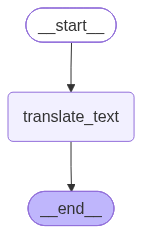

In [9]:
subgraph_builder = StateGraph(ParentState)

subgraph_builder.add_node("translate_text", translate_text)
subgraph_builder.add_edge(START,"translate_text")
subgraph_builder.add_edge("translate_text",END)

subgraph = subgraph_builder.compile()

subgraph

In [7]:
def generate_answer(state: ParentState):

    answer = parent_llm.invoke(f"You are a helpful assistant. Answer clearly.\n\nQuestion: {state['question']}").content
    return {'answer_eng': answer}

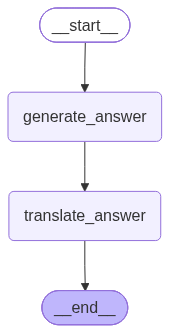

In [8]:
parent_builder= StateGraph(ParentState)
parent_builder.add_node("generate_answer",generate_answer)
parent_builder.add_node("translate_answer",subgraph)
parent_builder.add_edge(START,"generate_answer")
parent_builder.add_edge("generate_answer","translate_answer")
parent_builder.add_edge("translate_answer",END)

graph = parent_builder.compile()

graph

In [10]:
graph.invoke({
    "question": "What is Agentic AI?"
})

{'question': 'What is Agentic AI?',
 'answer_eng': '**Agentic AI** refers to **artificial intelligence systems capable of autonomously identifying goals, planning steps to achieve them, and taking actions to pursue those goals without continuous human intervention**. It moves beyond *reactive* AI (e.g., chatbots that answer questions) to *proactive* AI that **acts as an "agent"**—making decisions and executing tasks to solve problems or fulfill objectives.\n\n### Key Characteristics:\n1. **Goal-Oriented**:  \n   - Sets its own goals (e.g., "Reduce customer wait times by 30%") and works toward them.  \n   - *Example*: An AI scheduling tool that reschedules meetings based on real-time calendar conflicts and user preferences, not just responding to a command.\n\n2. **Autonomy & Proactivity**:  \n   - Acts independently to adapt to new situations (e.g., an autonomous vehicle rerouting around traffic).  \n   - *Contrast with standard AI*: A reactive AI (like current chatbots) *responds* to 